<a href="https://colab.research.google.com/github/SyedAliAsghar-512/TextOriginMiner/blob/main/notebooks/02_baseline_detection1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS-311 · P04 · M1: EDA plots (Product lead)
Label counts, class imbalance, article length and top words on cleaned data. Runs on its own, top to bottom.
(The M2 baseline detection model goes below this later.)
**Save to GitHub:** File → Save a copy in GitHub → `notebooks/02_baseline_detection.ipynb`

In [1]:
!pip install -q datasets
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

SEED = 42
sns.set_theme(style="whitegrid")

## 1. Load and clean (same cleaning cell as the rest of the team)

In [2]:
# ---- Load + clean the data (this same cell is in every team notebook, so everyone gets identical data) ----
import re, html, unicodedata
import pandas as pd
from datasets import load_dataset

ERROR_PREFIX = "Error: Error communicating with OpenAI"   # failed GPT-4o API calls, not real articles

# Website boilerplate lines found in human texts but (almost) never in AI texts (from the Data lead's report).
# Removed only when a WHOLE line matches, so real sentences are never cut.
NAV_LINES = {
    "The New York Times", "Site Navigation", "Site Search Navigation", "Site Mobile Navigation",
    "Slideshow controls", "Recent Episodes", "What's Next", "transcript", "Covid-19Guidance", "Archive",
    "Supported by", "United States", "Credits", "Data", "Nursing Homes", "Vaccines", "Treatments",
    "Global Vaccinations", "Deaths Above Normal", "Colleges and Universities", "Your County’s Risk",
    "Hospitals Near You", "Your Places",
}
# Template lines in AI texts such as "By [Your Name]", "Published: [Date]", "By Your Name"
PLACEHOLDER_LINE = re.compile(
    r"^\s*(?:by|written by|published|date|author)\b[^\n]{0,30}\[[^\]\n]{1,40}\][^\n]{0,20}$|^\s*by your name\s*$", re.I)

def clean_text(text):
    text = unicodedata.normalize("NFKC", html.unescape(text))
    text = re.sub(r"<[^<>\n]{1,50}>", " ", text)                    # HTML tags
    text = re.sub(r"\*\*|__", "", text)                              # markdown bold
    text = re.sub(r"(?m)^[ \t]*#{1,6}[ \t]*", "", text)              # markdown headings
    lines = [l for l in text.split("\n")
             if l.strip() not in NAV_LINES and not PLACEHOLDER_LINE.match(l)]
    text = re.sub(r"^\s*(?:Comments\b|Title:)\s*", "", "\n".join(lines))   # leading "Comments" / "Title:"
    text = re.sub(r"[ \t]+", " ", text)
    return re.sub(r"\n\s*\n+", "\n\n", text).strip()

def load_clean(min_words=50):
    ds = load_dataset("Rajarshi-Roy-research/Defactify_Text_Dataset")
    df = pd.concat([ds[s].to_pandas().assign(split=s) for s in ds.keys()], ignore_index=True)
    df.columns = [c.lower() for c in df.columns]                     # text, label_a, label_b, split
    report = {"rows_before": len(df)}

    df["text"] = df["text"].fillna("")
    empty = df["text"].str.strip() == ""
    report["missing_or_empty"] = int(empty.sum()); df = df[~empty]

    error = df["text"].str.lstrip().str.startswith(ERROR_PREFIX)
    report["api_error_texts"] = int(error.sum()); df = df[~error].copy()

    df["text"] = df["text"].map(clean_text)
    df["n_words"] = df["text"].str.split().str.len()
    short = df["n_words"] < min_words
    report[f"under_{min_words}_words"] = int(short.sum()); df = df[~short].copy()

    df["key"] = df["text"].str.lower().str.split().str.join(" ")
    n = len(df); df = df.drop_duplicates(["split", "key"])
    report["duplicates_within_split"] = n - len(df)
    in_eval = set(df.loc[df["split"] != "train", "key"])
    leak = (df["split"] == "train") & df["key"].isin(in_eval)
    report["train_copies_of_eval_texts"] = int(leak.sum())
    df = df[~leak].drop(columns="key").reset_index(drop=True)

    report["rows_after"] = len(df)
    for k, v in report.items():
        print(f"{k:>28}: {v:,}")
    return df, report

In [3]:
df, report = load_clean()
df["class"] = df["label_a"].map({0: "Human", 1: "AI"})

HUMAN = "Human_Story"     # capital S
order = [HUMAN] + sorted(x for x in df["label_b"].unique() if x != HUMAN)
print(order)

README.md:   0%|          | 0.00/2.69k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 86.2MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/51247 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10983 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10963 [00:00<?, ? examples/s]

                 rows_before: 73,193
            missing_or_empty: 85
             api_error_texts: 343
              under_50_words: 1,079
     duplicates_within_split: 62
  train_copies_of_eval_texts: 26
                  rows_after: 71,598
['Human_Story', 'GPT-4o', 'Gemma-2-9B', 'Llama-8B', 'Mistral-7B', 'Qwen-2-72B', 'Yi-Large']


## 2. Labels and class imbalance

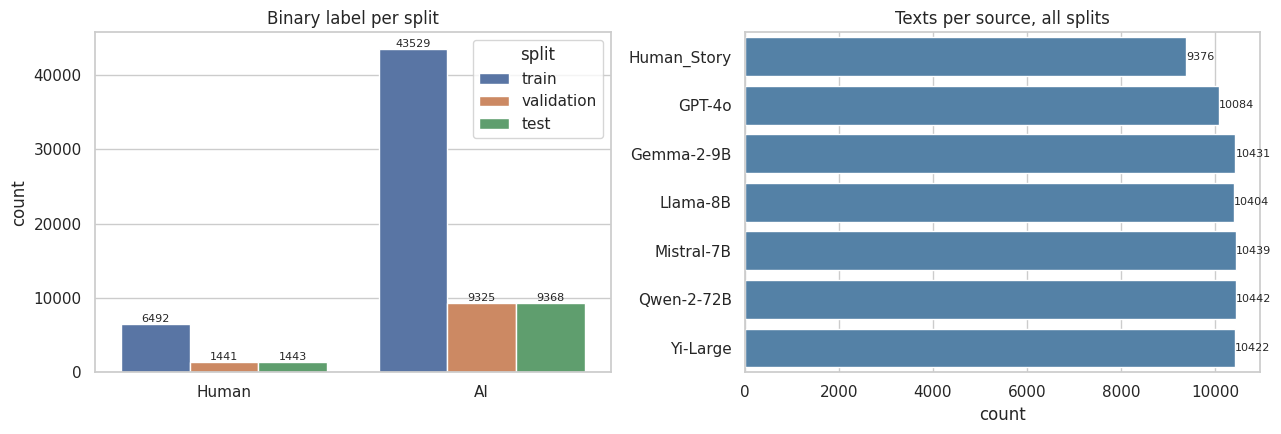

Human: 9376 (13.1%) | AI: 62222 (86.9%) | ratio 1 : 6.6
Always-predict-AI accuracy = 86.9%


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=df, x="class", hue="split", order=["Human", "AI"], ax=axes[0])
axes[0].set_title("Binary label per split"); axes[0].set_xlabel("")
for c in axes[0].containers:
    axes[0].bar_label(c, fontsize=8)

sns.countplot(data=df, y="label_b", order=order, ax=axes[1], color="steelblue")
axes[1].set_title("Texts per source, all splits"); axes[1].set_ylabel("")
axes[1].bar_label(axes[1].containers[0], fontsize=8)
plt.tight_layout(); plt.show()

n_h = (df.label_a == 0).sum(); n_a = (df.label_a == 1).sum()
print(f"Human: {n_h} ({n_h/len(df):.1%}) | AI: {n_a} ({n_a/len(df):.1%}) | ratio 1 : {n_a/n_h:.1f}")
print(f"Always-predict-AI accuracy = {n_a/len(df):.1%}")

## 3. Article length

         count   mean     std   min    25%    50%    75%       max
class                                                             
AI     62222.0  454.1   117.7  50.0  368.0  440.0  525.0    4653.0
Human   9376.0  834.3  2217.8  50.0  271.0  408.0  821.2  107318.0


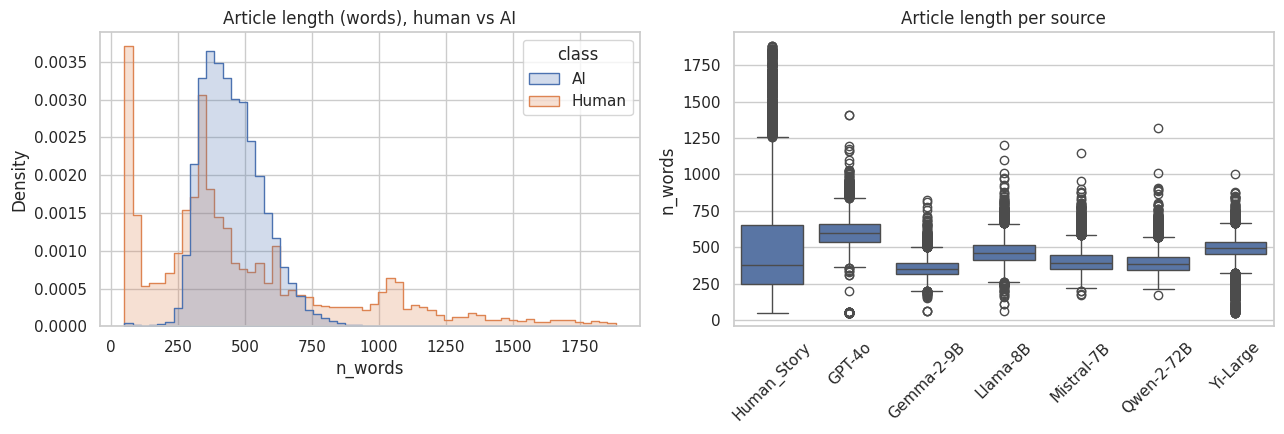

In [5]:
print(df.groupby("class")["n_words"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
upper = df["n_words"].quantile(0.99)    # cut the extreme tail so the plot is readable

sns.histplot(data=df[df.n_words <= upper], x="n_words", hue="class",
             bins=60, stat="density", common_norm=False, element="step", ax=axes[0])
axes[0].set_title("Article length (words), human vs AI")

sns.boxplot(data=df[df.n_words <= upper], x="label_b", y="n_words", order=order, ax=axes[1])
axes[1].set_title("Article length per source"); axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

## 4. Top words (cleaned text, stopwords removed)

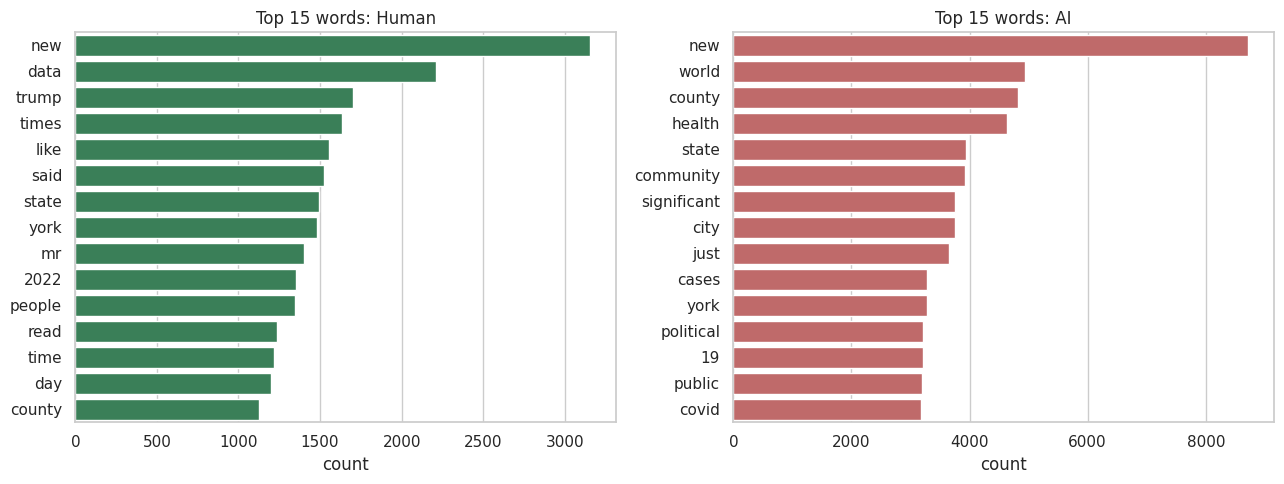

In [6]:
train = df[df["split"] == "train"]
N = min(1000, train["label_b"].value_counts().min())
sample = train.groupby("label_b").sample(n=N, random_state=SEED)

def top_words(texts, k=15):
    cv = CountVectorizer(stop_words="english", max_features=5000)
    X = cv.fit_transform(texts)
    counts = np.asarray(X.sum(axis=0)).ravel()
    vocab = np.array(cv.get_feature_names_out())
    idx = counts.argsort()[::-1][:k]
    return pd.DataFrame({"word": vocab[idx], "count": counts[idx]})

human_top = top_words(sample.loc[sample["class"] == "Human", "text"])
ai_top    = top_words(sample.loc[sample["class"] == "AI", "text"])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=human_top, y="word", x="count", color="seagreen", ax=axes[0])
axes[0].set_title("Top 15 words: Human")
sns.barplot(data=ai_top, y="word", x="count", color="indianred", ax=axes[1])
axes[1].set_title("Top 15 words: AI")
for ax in axes:
    ax.set_ylabel("")
plt.tight_layout(); plt.show()

## 5. Numbers for the findings

In [7]:
print(f"Cleaned data: {len(df):,} texts ({report['rows_before'] - len(df):,} removed by cleaning)")
print(f"Human share {n_h/len(df):.1%} | ratio 1 : {n_a/n_h:.1f} | always-AI accuracy {n_a/len(df):.1%}")
print("Median length (words):", df.groupby("class")["n_words"].median().to_dict())
print("Median length per source:", df.groupby("label_b")["n_words"].median().reindex(order).to_dict())

Cleaned data: 71,598 texts (1,595 removed by cleaning)
Human share 13.1% | ratio 1 : 6.6 | always-AI accuracy 86.9%
Median length (words): {'AI': 440.0, 'Human': 408.0}
Median length per source: {'Human_Story': 408.0, 'GPT-4o': 597.0, 'Gemma-2-9B': 350.0, 'Llama-8B': 461.0, 'Mistral-7B': 394.0, 'Qwen-2-72B': 384.0, 'Yi-Large': 495.0}


## EDA Findings
1. **Cleaning:** 1,595 of 73,193 texts removed (see the Data lead's quality table); 71,598 remain.
2. **Class imbalance:** human texts are 13.1% (1 : 6.6). Always predicting "AI" gives 86.9% accuracy, so we use macro-F1 and human-class recall.
3. **Length:** median 408 words (human) vs 440 (AI). Human lengths are far more spread out (std ≈ 2,218 vs 118 words), because a few articles are extremely long (up to 107,318 words).
4. **Length per source:** shortest Gemma-2-9B (350 words median), longest GPT-4o (597 words median).
5. **Top words:** human texts lean towards news-style and named-entity words ("trump", "times", "york", "mr", "said", "2022", "data"); AI texts towards generic, abstract words ("world", "community", "health", "significant", "public", "political", "cases", "covid").

Style features and the hypothesis test are in the Mining lead's notebook.